## Lab: RNN with Forecasting

### Wind Turbine Power Prediction with RNN

This lab uses a Recurrent Neural Network to predict wind turbine power output.
* [Data link](https://www.kaggle.com/code/ahmedfathygwely/wind-turbine-dataset-machine-learning-rnn-times/input)

### Step 0: Load libraries & Data

In [1]:
# Step 0: Load libraries & Data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import math

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Load the data
df = pd.read_csv('T1.csv')

2026-10-12 18:20:48.286500: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# Display basic information
display(df.shape)
display(df.head())
print(df.columns)

(50530, 5)

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
0,01 01 2018 00:00,380.047791,5.311336,416.328908,259.994904
1,01 01 2018 00:10,453.769196,5.672167,519.917511,268.641113
2,01 01 2018 00:20,306.376587,5.216037,390.900016,272.564789
3,01 01 2018 00:30,419.645905,5.659674,516.127569,271.258087
4,01 01 2018 00:40,380.650696,5.577941,491.702972,265.674286


Index(['Date/Time', 'LV ActivePower (kW)', 'Wind Speed (m/s)',
       'Theoretical_Power_Curve (KWh)', 'Wind Direction (°)'],
      dtype='object')


### Step 1: Prepare the data

In [3]:
# Step 1: Prepare the data
df['Date/Time'] = pd.to_datetime(df['Date/Time'], format='%d %m %Y %H:%M') # Convert date/time to a proper forma
print(df.isnull().sum()) # Check for missing values
df.describe()

Date/Time                        0
LV ActivePower (kW)              0
Wind Speed (m/s)                 0
Theoretical_Power_Curve (KWh)    0
Wind Direction (°)               0
dtype: int64


,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
count,50530,50530.000000,50530.000000,50530.000000,50530.000000
mean,2018-07-01 20:01:30.065307648,1307.684332,7.557952,1492.175463,123.687559
min,2018-01-01 00:00:00,-2.471405,0.000000,0.000000,0.000000
25%,2018-04-03 05:22:30,50.677890,4.201395,161.328167,49.315437
50%,2018-06-30 16:15:00,825.838074,7.104594,1063.776283,73.712978
75%,2018-09-26 18:57:30,2482.507568,10.300020,2964.972462,201.696720
max,2018-12-31 23:50:00,3618.732910,25.206011,3600.000000,359.997589
std,NaN,1312.459242,4.227166,1368.018238,93.443736


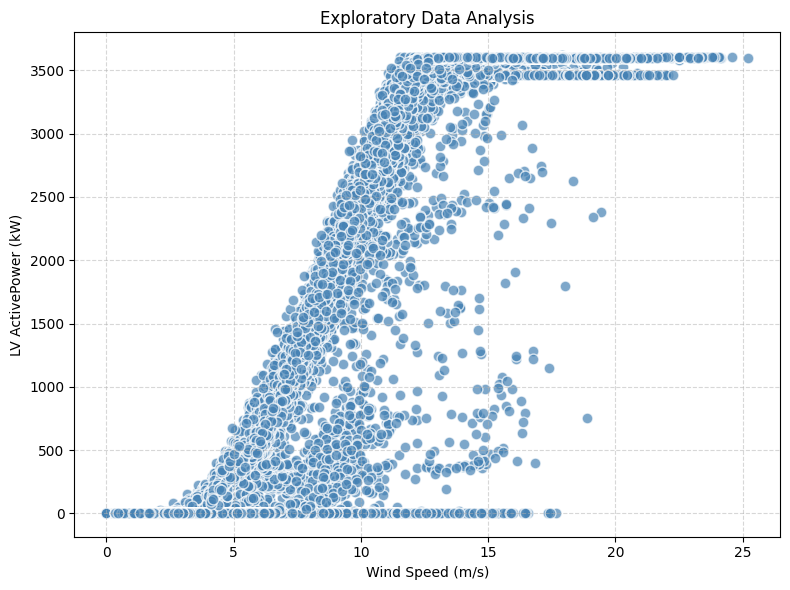

In [4]:
# print(df['LV ActivePower (kW)'])
# print(df['Wind Speed (m/s)'])

# generate sample data
np.random.seed(42)
x = df['Wind Speed (m/s)']
y = df['LV ActivePower (kW)']

# create the scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7, c='steelblue', edgecolors='white', s=60)

# add labels and title
plt.xlabel('Wind Speed (m/s)')
plt.ylabel('LV ActivePower (kW)')
plt.title('Exploratory Data Analysis')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [5]:
# Select and normalize features

features = ['LV ActivePower (kW)', 'Wind Speed (m/s)', 'Theoretical_Power_Curve (KWh)']
data = df[features]

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

### Step 2: Create sequences

In [6]:
# Step 2: Create sequences

def create_sequences(scaled_data, seq_length):
    X, y = [], []
    for i in range(len(scaled_data) - seq_length):
        X.append(scaled_data[i:i + seq_length])      # capital X
        y.append(scaled_data[i + seq_length])
    return np.array(X), np.array(y)

seq_length = 24
X, y = create_sequences(scaled_data, seq_length)

X.shape, y.shape

((50506, 24, 3), (50506, 3))

### Step 3: Split the data

In [7]:
# Step 3: Split the data

train_size = int(len(X) * 0.8)

X_train, X_test = X[:train_size], X[train_size:]

y_train, y_test = y[:train_size], y[train_size:]

X_train.shape, X_test.shape, y_train.shape, y_test.shape 

((40404, 24, 3), (10102, 24, 3), (40404, 3), (10102, 3))

### Step 4: Build the RNN Model

In [8]:
# Step 4: Build the RNN Model

model = Sequential()

model.add(LSTM( 50, activation='tanh', input_shape=(seq_length, 3), return_sequences=True ))
model.add(Dropout(0.2))

model.add(LSTM(50, activation='tanh'))
model.add(Dropout(0.2))

model.add(Dense(1)) # Final Dense layer — 1 unit for power output

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

/usr/local/Caskroom/miniconda/base/envs/learn-env/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 50)         │        10,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,051 (121.29 KB)

 Trainable params: 31,051 (121.29 KB)

 Non-trainable params: 0 (0.00 B)

### Step 5: Train the model

Epoch 1/30
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0123
Epoch 1: val_loss improved from None to 0.00512, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - loss: 0.0123 - val_loss: 0.0051
Epoch 2/30
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0071
Epoch 2: val_loss improved from 0.00512 to 0.00427, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - loss: 0.0071 - val_loss: 0.0043
Epoch 3/30
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0063
Epoch 3: val_loss improved from 0.00427 to 0.00412, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - loss: 0.0063 - val_loss: 0.0041
Epoch 4/30
1258/1263 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0060
Epoch 4: val_loss did not improve from 0.00412
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 1

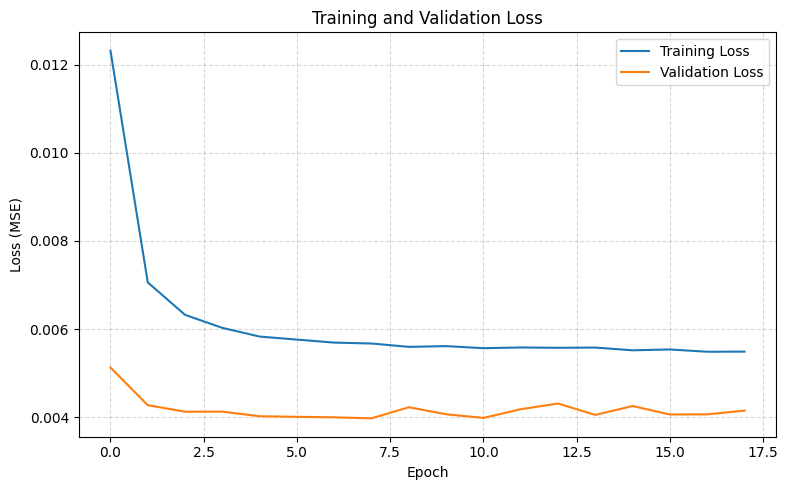

In [9]:
# Step 5: Train the model

# Use only the power column (first feature) as the target
y_train = y_train[:, 0]
y_test  = y_test[:, 0]

# 1. Set up callbacks
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    'best_model.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

# 2. Fit the model
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stop, checkpoint],
    verbose=1
)

# 3. Plot the training history
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Step 6: Evaluate on the test data and visualize the results

316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
Test MSE:  52098.78
Test RMSE: 228.25
Test R²:   0.9711


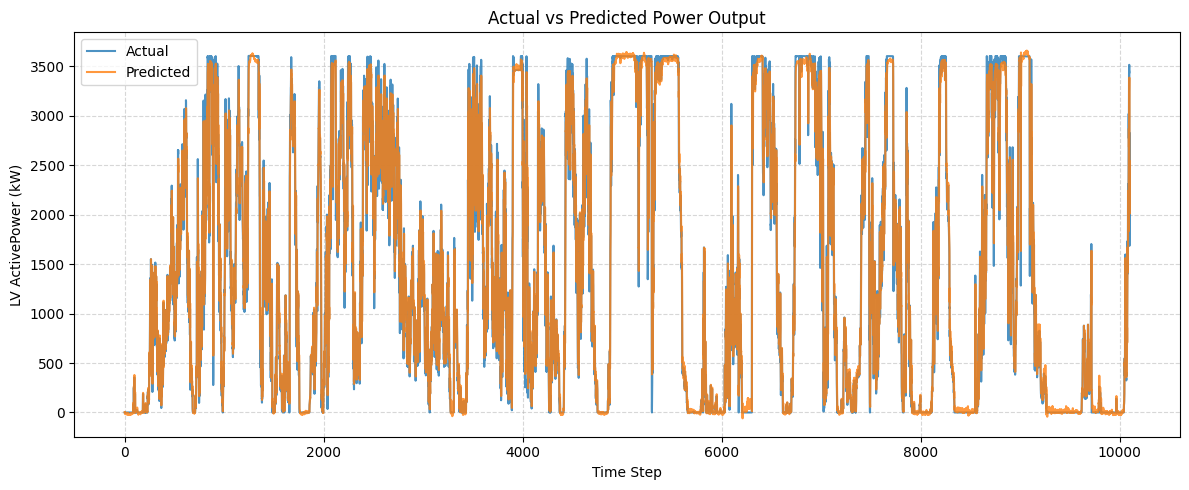

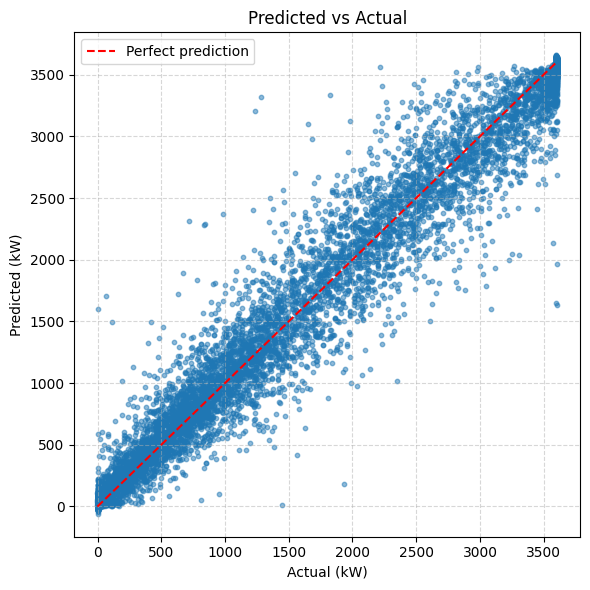

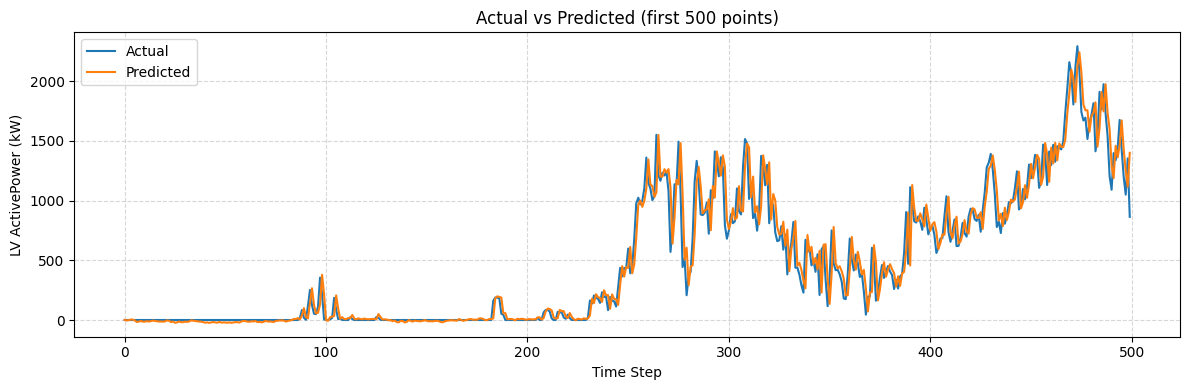

In [10]:
# Step 6: Evaluate and visualize

# 1. Generate predictions
y_pred = model.predict(X_test)

# 2. Inverse-scale predictions and true values
# The scaler was fit on 3 features, so we need placeholder arrays
# of the same shape, then extract only the power column (index 0)

def inverse_scale_power(scaler, values):
    # values is shape (n_samples, 1) or (n_samples,)
    dummy = np.zeros((len(values), 3))
    dummy[:, 0] = values.flatten()   # put power in the first column
    return scaler.inverse_transform(dummy)[:, 0]

y_test_inv = inverse_scale_power(scaler, y_test)
y_pred_inv = inverse_scale_power(scaler, y_pred)

# 3. Calculate evaluation metrics
mse  = mean_squared_error(y_test_inv, y_pred_inv)
rmse = math.sqrt(mse)
r2   = r2_score(y_test_inv, y_pred_inv)

print(f'Test MSE:  {mse:.2f}')
print(f'Test RMSE: {rmse:.2f}')
print(f'Test R²:   {r2:.4f}')

# 4. Plot predictions vs actual values

# Time-series plot
plt.figure(figsize=(12, 5))
plt.plot(y_test_inv, label='Actual', alpha=0.8)
plt.plot(y_pred_inv, label='Predicted', alpha=0.8)
plt.xlabel('Time Step')
plt.ylabel('LV ActivePower (kW)')
plt.title('Actual vs Predicted Power Output')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Scatter plot
plt.figure(figsize=(6, 6))
plt.scatter(y_test_inv, y_pred_inv, alpha=0.5, s=10)
plt.plot([y_test_inv.min(), y_test_inv.max()],
         [y_test_inv.min(), y_test_inv.max()],
         'r--', label='Perfect prediction')
plt.xlabel('Actual (kW)')
plt.ylabel('Predicted (kW)')
plt.title('Predicted vs Actual')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 5. Optional: zoom in on a window (first 500 points)
plt.figure(figsize=(12, 4))
plt.plot(y_test_inv[:500], label='Actual')
plt.plot(y_pred_inv[:500], label='Predicted')
plt.xlabel('Time Step')
plt.ylabel('LV ActivePower (kW)')
plt.title('Actual vs Predicted (first 500 points)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()